## Two-stage anchor-based detector: Faster R-CNN
HW2, notebook 2/5 (Kaggle GPU). Writes `results_02_*.csv`, `final_02.pt` and `submission_02_faster_rcnn.csv` to `/kaggle/working`.

**Needs on Kaggle:** GPU accelerator (T4 / P100), **Internet ON** (pretrained weights are downloaded), inputs: the competition + the output of notebook 01 (or the dataset made from it). No API keys.

**Shared protocol (notebooks 02-05)**
- Data: frames exported by notebook 01 (every 5th frame, ignored regions grayed out). Split **by clip**: 5 GroupKFold folds (grouped by source flight) from notebook 01.
- Cross-validation: every config is trained on `FOLDS_TO_RUN` folds and scored on the held-out clips with the COCO evaluator (ignored regions = `iscrowd`, up to 500 boxes per image). Tables show mean and std over folds.
- Final: the best config (mean mAP) is retrained on all training frames, checked once on the official `val` clips (original resolution, every 5th frame) and used to write the test submission.
- Same metrics everywhere: mAP, AP50, AP_small / medium / large (COCO size buckets), and GPU inference ms per image.

**Model and why**
- torchvision **Faster R-CNN ResNet50-FPN**, COCO-pretrained, new 8-class box predictor. FPN has a stride-4 level, which 10-30 px objects need; the torchvision MobileNet-FPN variants only use stride 16/32 features, so they were not considered. Mixed precision keeps R50 fast enough.
- Input: shorter side 544 / longer side up to 960 (about half of the full-HD frame): a compromise between speed and small objects.
- Training: SGD, warmup + cosine, flip and brightness augmentation, few epochs (fine-tuning from COCO).

**Configs (each adds one idea to the previous)**
- `C0_default`: torchvision defaults.
- `C1_anchors_proposals`: anchor sizes taken from the GT box-size quantiles (default 32-512 is too large for tiny objects) and more RPN proposals / detections per image (dense scenes).
- `C2_giou_loss`: C1 + GIoU instead of Smooth-L1 for the RoI box regression (IoU-based loss, gives gradients for badly overlapping boxes; computed on box deltas, which is exact because IoU is invariant to the shared proposal box).

In [1]:
import os, io, json, time, math, random, shutil, contextlib
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

SEED = 0
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE -> turn on a GPU in the session options")

INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")

def find_all(pattern, depth=5):
    # search attached inputs at increasing nesting depth (Kaggle nests inputs differently per source)
    for d in range(depth):
        hit = sorted(INPUT.glob("/".join(["*"] * d + [pattern])))
        if hit:
            return hit
    return []

def find(pattern):
    hit = find_all(pattern)
    if not hit:
        raise FileNotFoundError(f"{pattern} not found under {INPUT}: check the attached inputs")
    return hit[0]

PREP = find("vd_prep/config.json").parent            # output of notebook 01
CFG = json.load(open(PREP / "config.json"))
TEST_CSV = find("test_images.csv"); ROOT = TEST_CSV.parent
VAL_DIR = find("val/annotations_coco.json").parent
FOLD = CFG["folds"]                                   # train clip -> fold id (GroupKFold by scene, from notebook 01)
METRICS = ["mAP", "AP50", "AP_s", "AP_m", "AP_l", "ms_per_img"]

DEVICE = "cuda"
EPOCHS, BS, LR = 3, 4, 0.005          # one epoch is about 7 min on a T4
FOLDS_TO_RUN = [0, 1]                  # folds used for CV (of 5)
MIN_SIZE, MAX_SIZE = 544, 960
VAL_STEP = 5
LABEL_SHIFT = 0                        # Faster R-CNN: label 0 is background, labels 1..8 = COCO category ids
NB = "02"

GPU: Tesla T4


### Data

In [2]:
def load_gt(path):
    # COCO ground truth; ignored regions (iscrowd=1) are copied to all 8 classes so they ignore detections of any class
    d = json.load(open(path))
    crowd = [a for a in d["annotations"] if a.get("iscrowd")]
    d["annotations"] = [a for a in d["annotations"] if not a.get("iscrowd")]
    nid = max([a["id"] for a in d["annotations"]], default=0) + 1
    for a in crowd:
        for c in range(1, 9):
            d["annotations"].append({**a, "id": nid, "category_id": c, "iscrowd": 1, "area": a["bbox"][2] * a["bbox"][3]})
            nid += 1
    gt = COCO()
    gt.dataset = d
    with contextlib.redirect_stdout(io.StringIO()):
        gt.createIndex()
    return gt

def coco_eval(gt, dets, img_ids):
    # standard COCO bbox metrics, up to 500 detections per image (as in the leaderboard)
    if not dets:
        return dict(mAP=0.0, AP50=0.0, AP_s=0.0, AP_m=0.0, AP_l=0.0)
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(gt, gt.loadRes(dets), "bbox")
        E.params.imgIds = list(img_ids)
        E.params.maxDets = [1, 10, 500]
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats                                  # s[1], s[3:6] already use maxDets[-1] = 500
    prec = E.eval["precision"][:, :, :, 0, -1]   # [IoU, recall, class] for all sizes at 500 dets (pycocotools' s[0] hardcodes 100)
    prec = prec[prec > -1]
    return dict(mAP=float(prec.mean()) if prec.size else -1.0, AP50=s[1], AP_s=s[3], AP_m=s[4], AP_l=s[5])

def write_submission(dets, path):
    # one row per test image: "class score x y w h ..." (0-based class, pixels, top-left corner, max 500 boxes)
    test = pd.read_csv(TEST_CSV)
    by = {}
    for d in dets:
        by.setdefault(d["image_id"], []).append(d)
    rows = []
    for iid in test.image_id:
        top = sorted(by.get(iid, []), key=lambda d: -d["score"])[:500]
        rows.append(" ".join(f"{d['category_id'] - 1} {d['score']:.4f} " + " ".join(f"{v:.1f}" for v in d["bbox"]) for d in top))
    sub = pd.DataFrame({"image_id": test.image_id, "PredictionString": rows})
    sub.to_csv(path, index=False)
    sample = find_all("sample_submission.csv")      # not shipped with this competition's data: ids come from test_images.csv
    if sample:
        assert list(sub.image_id) == list(pd.read_csv(sample[0]).image_id), "image ids differ from sample_submission.csv"
    print(f"saved {path}: {len(sub)} rows, {sum(map(bool, rows))} with detections, {sum(len(r.split()) // 6 for r in rows)} boxes")

In [3]:
# training frames exported by notebook 01 (ignored regions already grayed out)
TJ = json.load(open(PREP / "train_coco.json"))
IMGS = {i["id"]: i for i in TJ["images"]}
GT_TRAIN = load_gt(PREP / "train_coco.json")

def fold_ids(f):
    # (train ids, held-out ids) for fold f; f=None -> all frames for training
    return ([i for i, m in IMGS.items() if FOLD[m["video"]] != f],
            [i for i, m in IMGS.items() if FOLD[m["video"]] == f])

def train_path(i):
    return PREP / "images/train" / IMGS[i]["file_name"]

# official val: raw frames at original resolution, every VAL_STEP-th frame of each clip (for speed)
VAL_GT = load_gt(VAL_DIR / "annotations_coco.json")
_idx = {(p.parent.name, p.name): p for p in (VAL_DIR / "images").rglob("*.jpg")}
_v = pd.DataFrame(VAL_GT.dataset["images"])
_v = _v[(_v.groupby("video").frame_id.rank(method="first").astype(int) - 1) % VAL_STEP == 0]
VAL_ITEMS = [(int(r.id), _idx[(r.video, Path(r.file_name).name)]) for r in _v.itertuples()]
VAL_IDS = [i for i, _ in VAL_ITEMS]
TEST_ITEMS = [(r.image_id, ROOT / r.file_name) for r in pd.read_csv(TEST_CSV).itertuples()]
print(f"{len(IMGS)} train frames | {len(VAL_ITEMS)} val frames | {len(TEST_ITEMS)} test frames")

4868 train frames | 571 val frames | 3811 test frames


In [4]:
import albumentations as A
from torch.utils.data import Dataset, DataLoader

ANNS = {}
for a in TJ["annotations"]:
    if not a.get("iscrowd"):
        ANNS.setdefault(a["image_id"], []).append(a)

# augmentation: flip + photometric only (boxes follow the flip)
AUG = A.Compose([A.HorizontalFlip(p=0.5), A.RandomBrightnessContrast(p=0.3)],
                bbox_params=A.BboxParams(format="coco", label_fields=["labels"], min_visibility=0.3))

def read_rgb(p):
    return cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)

class DetDS(Dataset):
    def __init__(self, ids):
        self.ids = list(ids)
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, k):
        iid = self.ids[k]; m = IMGS[iid]; W, H = m["width"], m["height"]
        boxes, labels = [], []
        for a in ANNS.get(iid, []):
            x, y, w, h = a["bbox"]
            x0, y0, x1, y1 = max(0, x), max(0, y), min(W, x + w), min(H, y + h)
            if x1 - x0 >= 1 and y1 - y0 >= 1:
                boxes.append([x0, y0, x1 - x0, y1 - y0]); labels.append(a["category_id"] + LABEL_SHIFT)
        o = AUG(image=read_rgb(train_path(iid)), bboxes=boxes, labels=labels)
        b = torch.tensor(o["bboxes"], dtype=torch.float32).reshape(-1, 4)
        b[:, 2:] += b[:, :2]                                    # xywh -> xyxy
        img = torch.from_numpy(o["image"]).permute(2, 0, 1).float() / 255
        return img, {"boxes": b, "labels": torch.tensor(o["labels"], dtype=torch.int64)}

class ImgDS(Dataset):
    def __init__(self, items):
        self.items = items
    def __len__(self):
        return len(self.items)
    def __getitem__(self, k):
        iid, p = self.items[k]
        return iid, torch.from_numpy(read_rgb(p)).permute(2, 0, 1)

def collate(b):
    return tuple(zip(*b))

def fit(model, ids, epochs=None):
    # SGD + linear warmup + cosine decay, mixed precision
    epochs = epochs or EPOCHS
    dl = DataLoader(DetDS(ids), batch_size=BS, shuffle=True, num_workers=4, collate_fn=collate, drop_last=True)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=1e-4)
    total = epochs * len(dl); warm = max(1, min(300, total // 10))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * s / total)))
    scaler = torch.amp.GradScaler("cuda")
    model.to(DEVICE).train()
    for ep in range(epochs):
        run = 0.0
        for k, (imgs, tgts) in enumerate(tqdm(dl, desc=f"epoch {ep + 1}/{epochs}", leave=False)):
            imgs = [i.to(DEVICE) for i in imgs]
            tgts = [{n: v.to(DEVICE) for n, v in t.items()} for t in tgts]
            with torch.autocast("cuda", dtype=torch.float16):
                loss = sum(model(imgs, tgts).values())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 10.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item()
        print(f"  epoch {ep + 1}: mean loss {run / len(dl):.4f}")
    return model

@torch.no_grad()
def detect(model, items, bs=8):
    # returns COCO-style detections in the pixel coordinates of the input images and GPU ms per image
    model.eval()
    dl = DataLoader(ImgDS(items), batch_size=bs, num_workers=4, collate_fn=collate)
    dets, t_model = [], 0.0
    for ids, imgs in tqdm(dl, desc="inference", leave=False):
        imgs = [i.to(DEVICE).float() / 255 for i in imgs]
        torch.cuda.synchronize(); t0 = time.time()
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(imgs)
        torch.cuda.synchronize(); t_model += time.time() - t0
        for iid, o in zip(ids, out):
            b = o["boxes"].float().cpu().numpy(); b[:, 2:] -= b[:, :2]
            for box, s, l in zip(b.tolist(), o["scores"].float().cpu().tolist(), o["labels"].cpu().tolist()):
                dets.append({"image_id": iid, "category_id": l - LABEL_SHIFT, "bbox": box, "score": s})
    return dets, 1000 * t_model / len(items)

def eval_fold(model, ids):
    dets, ms = detect(model, [(i, train_path(i)) for i in ids])
    return {**coco_eval(GT_TRAIN, dets, ids), "ms_per_img": ms}

def anchor_stats():
    # GT box size (sqrt of area) after the model's own resize: this is what the anchors have to cover
    s = []
    for a in TJ["annotations"]:
        if a.get("iscrowd"):
            continue
        m = IMGS[a["image_id"]]
        sc = min(MIN_SIZE / min(m["width"], m["height"]), MAX_SIZE / max(m["width"], m["height"]))
        s.append(math.sqrt(a["bbox"][2] * a["bbox"][3]) * sc)
    return np.quantile(np.array(s), [.05, .25, .5, .75, .95, .99])

### Model builder

In [5]:
import torch.nn.functional as F
import torchvision.models.detection.roi_heads as roi_heads_mod
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import generalized_box_iou_loss, box_iou

q = anchor_stats()
print("GT box sqrt(area) quantiles 5/25/50/75/95/99 % after resize:", q.round(1))
# one size per FPN level (strides 4..64), geometric ladder from the smallest to the largest objects
DATA_ANCHORS = [max(4, int(round(x))) for x in np.geomspace(q[0], q[-1], 5)]
print("data-driven anchor sizes:", DATA_ANCHORS, "| torchvision default: [32, 64, 128, 256, 512]")

# GIoU box loss for the RoI head. Deltas are decoded against a unit reference box: both boxes share the
# same reference, and IoU/GIoU do not change under that shared axis-aligned shift+scale
_ORIG_LOSS = roi_heads_mod.fastrcnn_loss
_W = torch.tensor([10.0, 10.0, 5.0, 5.0])                    # box-coder weights of the RoI head

def _unit_box(d):
    d = d.float() / _W.to(d.device)
    cx, cy = d[:, 0], d[:, 1]
    w, h = d[:, 2].clamp(max=math.log(1000 / 16)).exp(), d[:, 3].clamp(max=math.log(1000 / 16)).exp()
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)

def fastrcnn_giou_loss(class_logits, box_regression, labels, regression_targets):
    labels = torch.cat(labels, 0); regression_targets = torch.cat(regression_targets, 0)
    cls_loss = F.cross_entropy(class_logits.float(), labels)
    pos = torch.where(labels > 0)[0]
    pred = box_regression.reshape(class_logits.shape[0], -1, 4)[pos, labels[pos]]
    box_loss = 2.0 * generalized_box_iou_loss(_unit_box(pred), _unit_box(regression_targets[pos]), reduction="sum") / labels.numel()
    return cls_loss, box_loss

def build(anchors=None, rpn_n=1000, dets=100, giou=False):
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1, weights_backbone=None,
                                min_size=MIN_SIZE, max_size=MAX_SIZE, box_score_thresh=0.001, box_detections_per_img=dets,
                                rpn_pre_nms_top_n_test=rpn_n, rpn_post_nms_top_n_test=rpn_n)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 9)
    if anchors:                                              # 3 ratios per location as before -> pretrained RPN head still fits
        m.rpn.anchor_generator = AnchorGenerator(sizes=tuple((s,) for s in anchors), aspect_ratios=((0.5, 1.0, 2.0),) * 5)
    roi_heads_mod.fastrcnn_loss = fastrcnn_giou_loss if giou else _ORIG_LOSS
    return m

CONFIGS = {
    "C0_default":           dict(),
    "C1_anchors_proposals": dict(anchors=DATA_ANCHORS, rpn_n=2000, dets=500),
    "C2_giou_loss":         dict(anchors=DATA_ANCHORS, rpn_n=2000, dets=500, giou=True),
}

GT box sqrt(area) quantiles 5/25/50/75/95/99 % after resize: [10.2 16.3 22.9 33.  63.  97.6]
data-driven anchor sizes: [10, 18, 32, 55, 98] | torchvision default: [32, 64, 128, 256, 512]


### Cross-validation of the three configs

In [6]:
# every config is trained on the same folds (cross-validation over clips) and scored on the held-out clips
rows = []
for name, cfg in CONFIGS.items():
    for f in FOLDS_TO_RUN:
        tr_ids, va_ids = fold_ids(f)
        seed_all()
        model = build(**cfg)
        t0 = time.time()
        fit(model, tr_ids)
        m = eval_fold(model, va_ids)
        rows.append({"config": name, "fold": f, **m, "train_min": (time.time() - t0) / 60})
        print(name, "fold", f, {k: round(v, 4) for k, v in m.items()})
        del model; torch.cuda.empty_cache()
folds_df = pd.DataFrame(rows)
folds_df.to_csv(WORK / f"results_{NB}_folds.csv", index=False)
display(folds_df.groupby("config")[METRICS].agg(["mean", "std"]).round(4))

  epoch 1: mean loss 1.1495
  epoch 2: mean loss 0.8488
  epoch 3: mean loss 0.7660
C0_default fold 0 {'mAP': 0.1676, 'AP50': np.float64(0.3292), 'AP_s': np.float64(0.058), 'AP_m': np.float64(0.207), 'AP_l': np.float64(0.4512), 'ms_per_img': 46.2607}
  epoch 1: mean loss 1.1347
  epoch 2: mean loss 0.8548
  epoch 3: mean loss 0.7758
C0_default fold 1 {'mAP': 0.1305, 'AP50': np.float64(0.2717), 'AP_s': np.float64(0.0463), 'AP_m': np.float64(0.201), 'AP_l': np.float64(0.3739), 'ms_per_img': 45.7834}
  epoch 1: mean loss 1.0186
  epoch 2: mean loss 0.8231
  epoch 3: mean loss 0.7632
C1_anchors_proposals fold 0 {'mAP': 0.1612, 'AP50': np.float64(0.3545), 'AP_s': np.float64(0.075), 'AP_m': np.float64(0.1967), 'AP_l': np.float64(0.3852), 'ms_per_img': 54.9385}
  epoch 1: mean loss 1.0076
  epoch 2: mean loss 0.8237
  epoch 3: mean loss 0.7629
C1_anchors_proposals fold 1 {'mAP': 0.1208, 'AP50': np.float64(0.2704), 'AP_s': np.float64(0.0511), 'AP_m': np.float64(0.1812), 'AP_l': np.float64(0.33

mAP            AP50            AP_s            AP_m  \
                        mean     std    mean     std    mean     std    mean   
config                                                                         
C0_default            0.1490  0.0263  0.3004  0.0406  0.0522  0.0083  0.2040   
C1_anchors_proposals  0.1410  0.0286  0.3124  0.0595  0.0630  0.0169  0.1889   
C2_giou_loss          0.1313  0.0252  0.3038  0.0543  0.0595  0.0135  0.1806   

                                AP_l         ms_per_img          
                         std    mean     std       mean     std  
config                                                           
C0_default            0.0043  0.4126  0.0547    46.0221  0.3375  
C1_anchors_proposals  0.0110  0.3591  0.0370    55.0380  0.1408  
C2_giou_loss          0.0094  0.3283  0.0254    55.5562  0.3021

**Observations:**
- The default config is best on CV mAP: 0.149 ± 0.026 vs 0.141 (C1) and 0.131 (C2). The fold std (~0.026) is larger than the differences, and fold 0 is better than fold 1 for every config.
- C1 (anchors 10-98 px from the box-size quantiles, 2000 proposals, 500 detections) helps small objects: AP_small 0.052 -> 0.063, AP50 0.300 -> 0.312. But it loses large and medium objects (AP_l 0.413 -> 0.359, AP_m 0.204 -> 0.189), so mAP drops, and it is slower (55 vs 46 ms per image).
- GIoU for the RoI box loss (C2) does not help: 0.131, lower on every size than C1. Within 3 epochs the IoU-based loss did not improve localisation over Smooth-L1.
- C0 keeps torchvision's 100 detections per image although frames have up to 180 objects; it still wins on mAP, so the cap mostly cuts low-scored boxes.

### Final model: retrain on all frames, check on official val

In [7]:
means = folds_df.groupby("config")[METRICS].mean()
best = means.mAP.idxmax()
print("best config by CV mAP:", best)
seed_all()
final = build(**CONFIGS[best])
fit(final, fold_ids(None)[0])
torch.save(final.state_dict(), WORK / "final_02.pt")

val_dets, val_ms = detect(final, VAL_ITEMS)
final_metrics = {**coco_eval(VAL_GT, val_dets, VAL_IDS), "ms_per_img": val_ms}
display(pd.Series(final_metrics).round(4).to_frame("official val"))

out = means.reset_index().assign(split="cv")
out = pd.concat([out, pd.DataFrame([{"config": best + " (final)", **final_metrics, "split": "val"}])], ignore_index=True)
out.insert(0, "model", "Faster R-CNN R50-FPN")
out.to_csv(WORK / "results_02_summary.csv", index=False)

best config by CV mAP: C0_default
  epoch 1: mean loss 1.1133
  epoch 2: mean loss 0.8414
  epoch 3: mean loss 0.7657


,official val
mAP,0.1637
AP50,0.3365
AP_s,0.0710
AP_m,0.1366
AP_l,0.3203
ms_per_img,46.5253


### What the two stages contribute
**RPN:** how many GT boxes (IoU >= 0.5) are covered by the top-N proposals, i.e. the upper bound for recall of the second stage.
**Second stage:** classification + box refinement of those proposals; compare final AP50 with the proposal recall.

In [8]:
@torch.no_grad()
def rpn_recall(model, items, gt, ns=(100, 300, 1000, 2000)):
    model.eval(); hit = dict.fromkeys(ns, 0); tot = 0
    for iid, p in items:
        anns = [a for a in gt.imgToAnns[iid] if not a["iscrowd"]]
        if not anns:
            continue
        img = torch.from_numpy(read_rgb(p)).permute(2, 0, 1).float().div(255).to(DEVICE)
        il, _ = model.transform([img])
        props, _ = model.rpn(il, model.backbone(il.tensors))
        sc = il.image_sizes[0][0] / img.shape[1]                      # resized height / original height
        G = torch.tensor([[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2], a["bbox"][1] + a["bbox"][3]] for a in anns], device=DEVICE) * sc
        iou = box_iou(G, props[0])
        for n in ns:
            hit[n] += (iou[:, :n].max(1).values >= 0.5).sum().item() if iou.shape[1] else 0
        tot += len(anns)
    return {f"recall@{n}": round(hit[n] / tot, 3) for n in ns}

print("RPN proposal recall (IoU>=0.5) on val:", rpn_recall(final, VAL_ITEMS[::3], VAL_GT))
print("detector AP50 on val:", round(final_metrics["AP50"], 3))

RPN proposal recall (IoU>=0.5) on val: {'recall@100': 0.591, 'recall@300': 0.728, 'recall@1000': 0.745, 'recall@2000': 0.745}
detector AP50 on val: 0.337


**Observations:**
- Final model (C0) on the official val: mAP 0.164, AP50 0.337, AP_small 0.071, 46.5 ms per image.
- The RPN limits recall: the top 100 proposals cover 59 % of the ground-truth boxes at IoU >= 0.5, 300 cover 73 %, and 1000 or 2000 only 74.5 %. A quarter of the objects never get a good proposal, mostly the tiny ones that are far from the smallest default anchor (32 px). More proposals do not fix this.
- The second stage turns the 74.5 % proposal recall into AP50 0.337: it removes duplicate and background proposals and refines the boxes, but misclassified and poorly localised boxes cost the rest.

### Failure cases
Frames with the most misses (red = missed GT) and false positives at score >= 0.4, IoU >= 0.5. Detections inside ignored regions are not counted as false positives.

,image_id,n_gt,missed,fp,score
492,2538,25,6,39,1.800000
491,2533,28,12,36,1.714286
417,2165,13,11,11,1.692308


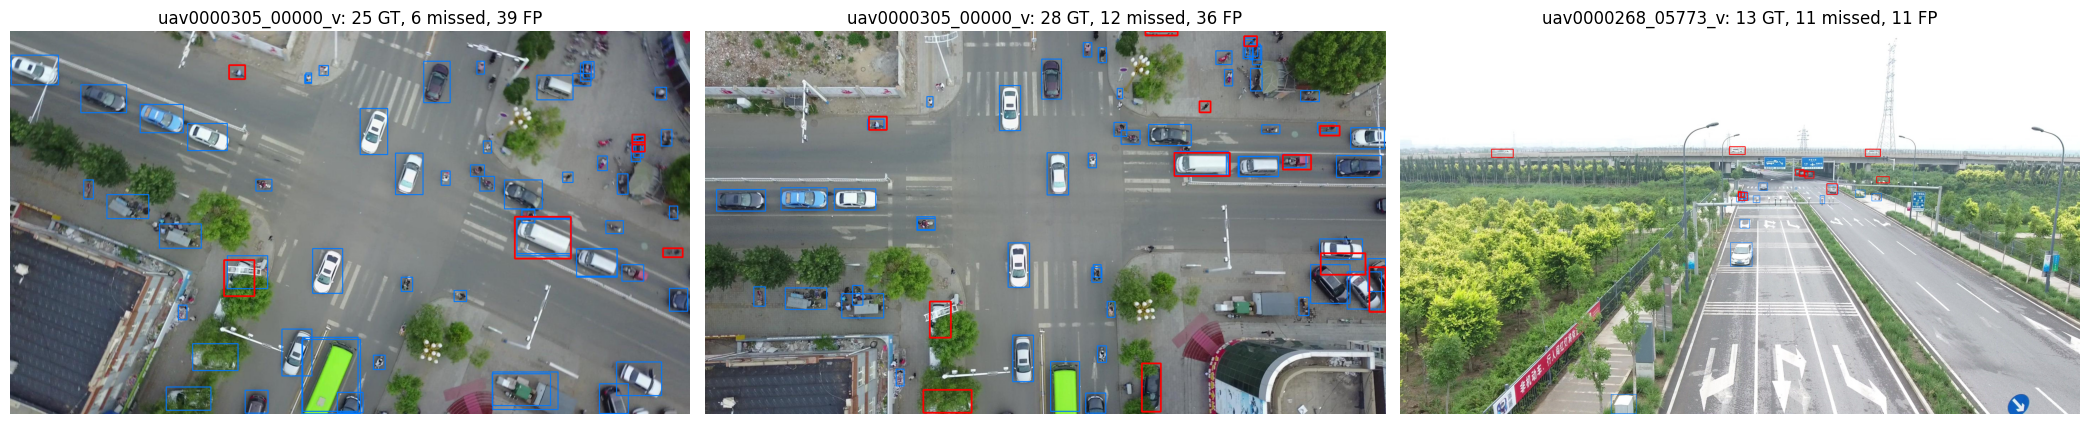

In [9]:
def failure_cases(dets, gt, ids, conf=0.4, k=3, min_gt=10):
    by = {}
    for d in dets:
        if d["score"] >= conf:
            by.setdefault(d["image_id"], []).append(d)
    xyxy = lambda b: [b[0], b[1], b[0] + b[2], b[1] + b[3]]
    rows = []
    for i in ids:
        anns = [a for a in gt.imgToAnns[i] if not a["iscrowd"]]
        crowd = [xyxy(a["bbox"]) for a in gt.imgToAnns[i] if a["iscrowd"] and a["category_id"] == 1]
        P = sorted(by.get(i, []), key=lambda d: -d["score"])
        if len(anns) < min_gt:
            continue
        G = torch.tensor([xyxy(a["bbox"]) for a in anns]); Gc = torch.tensor([a["category_id"] for a in anns])
        used, fp = set(), 0
        for d in P:
            b = torch.tensor([xyxy(d["bbox"])])
            iou = box_iou(b, G)[0] * (Gc == d["category_id"])
            iou[list(used)] = 0
            j = int(iou.argmax())
            if iou[j] >= 0.5:
                used.add(j)
            else:
                cx, cy = b[0, 0] + d["bbox"][2] / 2, b[0, 1] + d["bbox"][3] / 2
                if not any(c[0] <= cx <= c[2] and c[1] <= cy <= c[3] for c in crowd):
                    fp += 1
        miss = [j for j in range(len(anns)) if j not in used]
        rows.append(dict(image_id=i, n_gt=len(anns), missed=len(miss), fp=fp, score=(len(miss) + fp) / len(anns), miss_idx=miss))
    cols = ["image_id", "n_gt", "missed", "fp", "score", "miss_idx"]
    return pd.DataFrame(rows, columns=cols).sort_values("score", ascending=False).head(k), by

worst, by = failure_cases(val_dets, VAL_GT, VAL_IDS)
display(worst.drop(columns="miss_idx"))
paths = dict(VAL_ITEMS)
fig, axes = plt.subplots(1, len(worst), figsize=(7 * len(worst), 5))
for ax, r in zip(np.atleast_1d(axes), worst.itertuples()):
    img = read_rgb(paths[r.image_id]); anns = [a for a in VAL_GT.imgToAnns[r.image_id] if not a["iscrowd"]]
    for d in by.get(r.image_id, []):
        x, y, w, h = map(int, d["bbox"]); cv2.rectangle(img, (x, y), (x + w, y + h), (0, 120, 255), 2)
    for j in r.miss_idx:
        x, y, w, h = map(int, anns[j]["bbox"]); cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 3)
    ax.imshow(img); ax.set_title(f"{VAL_GT.imgs[r.image_id]['video']}: {r.n_gt} GT, {r.missed} missed, {r.fp} FP"); ax.axis("off")
plt.tight_layout(); plt.savefig(WORK / "failure_cases_02.png", dpi=110); plt.show()

**Failure cases:**
- **Top-down intersection, uav0000305 (25 GT, 6 missed, 39 FP):** the misses are tiny motorbikes and pedestrians near the right edge and a white van that has a box but is still missed, so the class is wrong (van vs car / truck). Most false positives are in the crowded roadside areas with parked tricycles and motorbikes. Causes: tiny size, class confusion between similar vehicle classes, density.
- **Same clip, later frame (28 GT, 12 missed, 36 FP):** objects partly hidden under trees (a car and a person in the lower middle) and vehicles cut by the right frame border are missed, plus the van again. Causes: occlusion and truncation.
- **Oblique view, uav0000268 (13 GT, 11 missed):** almost all misses are distant vehicles on the far road and the bridge, only a few pixels tall after resizing to 960 px. Cause: object size at long range, where the smallest anchor (32 px) and the RPN recall limit hit hardest.

### Test predictions and submission


In [10]:
test_dets, _ = detect(final, TEST_ITEMS)
write_submission(test_dets, WORK / "submission_02_faster_rcnn.csv")